# 05 · Bell pair on real IBM hardware

Real qubits are noisy. Gates are slightly mis-calibrated, qubits lose their state over time
(T1/T2, see notebook 06), and readout sometimes reports the wrong bit. On hardware the Bell pair
will show some `01`/`10` counts that the ideal simulator never produces.

## One-time account setup
1. Sign up at **https://quantum.cloud.ibm.com** (the free **Open plan** gives you a monthly QPU-time allowance).
2. Create an **instance** if you don't already have one, then copy its **CRN** (it starts with `crn:v1:bluemix:...`).
3. Create an **API key** from the dashboard and copy it. You only see it once.
4. Set `SAVE_ACCOUNT = True` below and run the cell once. It asks for the key with a hidden prompt and saves it to
   `~/.qiskit/qiskit-ibm.json`, so the key **never appears in this notebook**. Then set `SAVE_ACCOUNT` back to `False`.

> Don't paste the API key into a cell as a string. Notebooks get shared and committed.

In [1]:
from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

SAVE_ACCOUNT = False   # <- set True, run once, set back to False

if SAVE_ACCOUNT:
    QiskitRuntimeService.save_account(
        channel="ibm_quantum_platform",
        token=getpass("IBM Quantum API key: "),
        instance=input("Instance CRN (blank = auto-select): ").strip() or None,
        set_as_default=True,
        overwrite=True,
    )
    print("Saved to ~/.qiskit/qiskit-ibm.json")

print("Saved accounts:", list(QiskitRuntimeService.saved_accounts()))

Saved accounts: []


## Choose a backend
With `USE_REAL_HARDWARE = False` the notebook uses **FakeTorino**, a local simulator loaded with a real
IBM device's noise model. Everything below runs offline, so you can try the workflow first.
Switch to `True` once your account is saved. The job then goes into a queue, which can take anywhere
from seconds to hours depending on demand.

In [2]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import hellinger_fidelity
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.executor_sampler import Sampler   # the current (client-side) Sampler primitive
from qiskit_ibm_runtime.fake_provider import FakeTorino

USE_REAL_HARDWARE = False
SHOTS = 4096
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # fixed series order: blue, orange, aqua

if USE_REAL_HARDWARE:
    service = QiskitRuntimeService()
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=2)
else:
    backend = FakeTorino()
print("Backend:", backend.name, f"({backend.num_qubits} qubits)")

Backend: fake_torino (133 qubits)


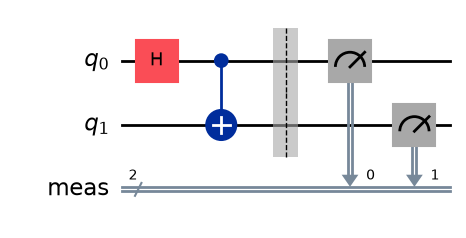

In [3]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
bell.measure_all()   # stores results in a register named 'meas'
bell.draw("mpl")

## Transpile to the device's native gates and qubit layout
Real devices only support a few native gates (IBM Heron: `cz`, `rz`, `sx`, `x`), and two-qubit gates
only work between physically connected qubits. The transpiler rewrites our `H`/`CNOT` circuit to fit.
The result is called an **ISA circuit**.

physical qubits used: [0, 1]


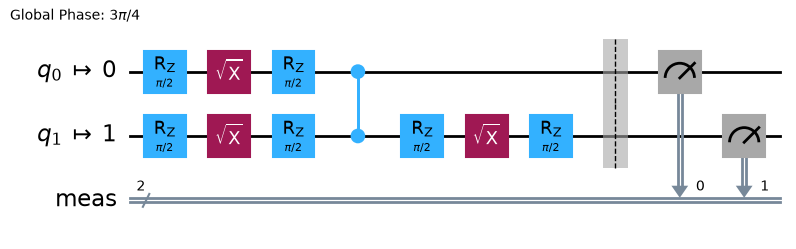

In [4]:
pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
isa_bell = pm.run(bell)
print("physical qubits used:", isa_bell.layout.final_index_layout())
isa_bell.draw("mpl", idle_wires=False)

In [5]:
# 1) Ideal reference: noiseless local simulation
ideal_sim = AerSimulator()
ideal_counts = ideal_sim.run(transpile(bell, ideal_sim), shots=SHOTS).result().get_counts()

# 2) The device (or its noisy fake twin)
sampler = Sampler(mode=backend)
job = sampler.run([isa_bell], shots=SHOTS)
print("job id:", job.job_id(), "<- save this; on real hardware you can fetch it later with service.job(job_id)")
hw_counts = job.result()[0].data.meas.get_counts()

job id: f472dc63-aa9b-4294-96c8-84f666709254 <- save this; on real hardware you can fetch it later with service.job(job_id)


ideal      P(00)+P(11) = 1.000   error (01/10) = 0.000
fake_torino P(00)+P(11) = 0.815   error (01/10) = 0.185
Hellinger fidelity (1 = identical distributions): 0.815


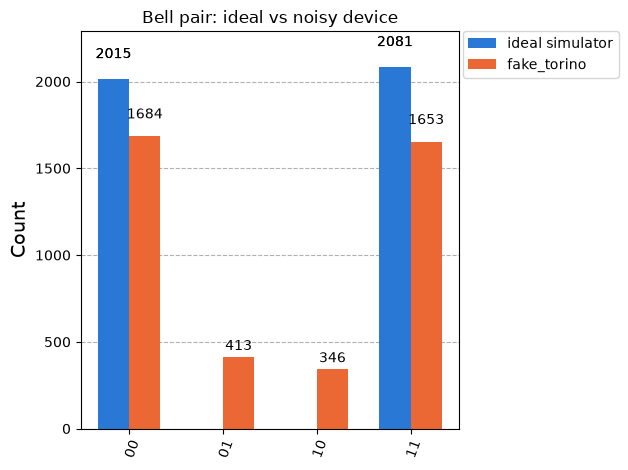

In [6]:
def summarize(name, c):
    total = sum(c.values())
    good = (c.get("00", 0) + c.get("11", 0)) / total
    print(f"{name:<10} P(00)+P(11) = {good:.3f}   error (01/10) = {1 - good:.3f}")

summarize("ideal", ideal_counts)
summarize(backend.name, hw_counts)
print(f"Hellinger fidelity (1 = identical distributions): {hellinger_fidelity(ideal_counts, hw_counts):.3f}")

plot_histogram([ideal_counts, hw_counts], legend=["ideal simulator", backend.name],
               color=COLORS[:2], title="Bell pair: ideal vs noisy device")

## Where the noise comes from
* **Readout error**: a `0` read out as `1` or the reverse, typically 0.5–3% per qubit. This is usually the biggest contributor for a circuit this short.
* **Two-qubit gate error**: the CNOT becomes several native gates including one `cz`/`ecr`, at roughly 0.3–1% error.
* **Decoherence (T1/T2)** while the circuit runs (notebook 06 simulates this).

The `01`/`10` bars are those errors showing up. Error **mitigation** (for example
`sampler.options.twirling`, readout mitigation) and error **correction** (notebook 07 is the
simplest example) are the two ways people fight them.

**Retrieve a past job** (on real hardware):
```python
job = QiskitRuntimeService().job("<job id>")
counts = job.result()[0].data.meas.get_counts()
```